# 08 : RQ4, généralisation à des sous-reddits absents de l'entraînement

**Question :** les modèles ont-ils appris à reconnaître une fake news, ou seulement à reconnaître la **communauté** (le sous-reddit) d'où vient la publication ? Dans Fakeddit, l'étiquette vient du sous-reddit et chaque sous-reddit est presque entièrement d'une seule classe : le sous-reddit seul prédit la classe avec une exactitude de 1,0.

**Principe :** on regroupe les 10 231 publications et on les redécoupe en **K plis** (K = 5 si possible), de deux façons :

| Découpage | Ce qu'il fait | Rôle |
|---|---|---|
| `aleatoire` | publications réparties au hasard (équilibre des classes respecté) | **contrôle** : mêmes tailles, mêmes modèles, mais les sous-reddits sont partagés |
| `sous_reddits` | un sous-reddit est entièrement dans **un seul** pli | le vrai test : les sous-reddits du test n'ont jamais été vus |

Pour chaque pli : le pli *k* sert de **test**, le pli *k+1* de **validation** (choix de C et du poids de la fusion), les autres de **entraînement**. Les modèles sont ceux du projet, avec le même protocole : **sous-reddit seul** (lecture du sous-reddit dans l'entraînement), E1 (TF-IDF), E2 (DistilBERT), E3d (CLIP), E4b (fusion précoce), E5b (fusion tardive).

**Avant de lancer (panneau de droite, Kaggle)**
1. **Add Input**, dataset : la version **nettoyée** (`train.tsv`, `val.tsv`, `test.tsv`). La cellule 2 s'arrête si les tailles ne sont pas 7 432 / 1 403 / 1 396.
2. **Add Input**, onglet **Notebooks** (ou *Your Work*) : la sortie de ton notebook `02_embeddings_e2_e3` **version v2** (elle contient `emb/txt_*.npy` et `emb/img_clip_vit_b32_*.npy`).
3. Aucun GPU ni Internet nécessaires. Compte quelques minutes (calcul sur processeur).

Lance les cellules dans l'ordre, puis **Save Version**, **Save & Run All**, et récupère `results/` et `figures/` dans l'onglet **Output**.

**Comment lire les résultats**
- On compare la Macro F1 de chaque modèle entre `aleatoire` et `sous_reddits`. Une **petite baisse** : le modèle s'appuie surtout sur le contenu. Une **grosse baisse** : il s'appuyait sur la communauté.
- Les deux découpages ont des **jeux de test différents** : on compare des moyennes sur les plis, pas des plis appariés. L'écart-type entre plis donne l'ordre de grandeur du bruit.
- Le nombre de sous-reddits est limité : chaque pli de test ne contient que quelques communautés, donc les résultats varient d'un pli à l'autre. La table par sous-reddit montre lesquels sont difficiles.
- Les étiquettes restent celles du sous-reddit, même pour un sous-reddit inconnu : le test mesure la généralisation à d'autres communautés, pas la vérité des faits.

In [1]:
# Cellule 1 : imports, graine, chemins
import os, glob, json, time, warnings, unicodedata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
N_JOBS = -1      # processeurs utilises pour choisir C ; mets 1 si le calcul se bloque

hits = glob.glob("/kaggle/input/**/train.tsv", recursive=True)
assert hits, "train.tsv introuvable : ajoute ton dataset avec Add Input"
P = os.path.dirname(hits[0]) + "/"

emb = glob.glob("/kaggle/input/**/emb/img_clip_vit_b32_train.npy", recursive=True)
assert emb, ("embeddings CLIP introuvables : Add Input, onglet Notebooks (ou Your Work), choisis la version v2 de "
             "ton notebook 02_embeddings_e2_e3 (sa sortie contient emb/img_clip_vit_b32_train.npy)")
EMB = os.path.dirname(emb[0]) + "/"
assert os.path.exists(EMB + "txt_train.npy"), "txt_train.npy manquant dans " + EMB

OUT = "/kaggle/working/"
for d in ("results/mlflow", "figures"):
    os.makedirs(OUT + d, exist_ok=True)
print("P   =", P)
print("EMB =", EMB)

P   = /kaggle/input/datasets/sahnounsahnoun/data-fakenewes/
EMB = /kaggle/input/notebooks/sahnounsahnoun/e2-e3-embeddings/emb/


In [2]:
# Cellule 2 : controle de version, embeddings, et regroupement des 10 231 publications
S = ["train", "val", "test"]
df = {s: pd.read_csv(P + s + ".tsv", sep="\t") for s in S}

ATTENDU = {"train": 7432, "val": 1403, "test": 1396}
for s in S:
    assert len(df[s]) == ATTENDU[s], (
        "%s : %d publications, %d attendues. Ce n'est pas la version nettoyee du dataset "
        "(l'ancienne version non nettoyee a 7792 / 1469 / 1450)." % (s, len(df[s]), ATTENDU[s]))

Xt = {s: np.load(EMB + "txt_%s.npy" % s) for s in S}                    # DistilBERT gele
Xi = {s: np.load(EMB + "img_clip_vit_b32_%s.npy" % s) for s in S}       # CLIP ViT-B/32 gele
for s in S:
    assert len(df[s]) == len(Xt[s]) == len(Xi[s]), (
        "%s : %d lignes dans le tsv, %d embeddings texte, %d embeddings image. "
        "Les embeddings viennent d'une autre version du dataset : relance 02." % (s, len(df[s]), len(Xt[s]), len(Xi[s])))

tout = pd.concat([df[s] for s in S], ignore_index=True)
assert tout["id"].is_unique, "identifiants en double"
N = len(tout)
y_all = tout["2_way_label"].values.astype(int)
sub_all = tout["subreddit"].fillna("inconnu").astype(str).values
titre_all = tout["clean_title"].astype(str).values
Xt_all = np.vstack([Xt[s] for s in S])
Xi_all = np.vstack([Xi[s] for s in S])
Xf_all = np.hstack([Xt_all, Xi_all])
print("publications :", N, "| sous-reddits :", len(set(sub_all)))

# un sous-reddit = une communaute ; sa classe = la classe majoritaire de ses publications
t_sub = pd.DataFrame({"sub": sub_all, "y": y_all}).groupby("sub")["y"].agg(n="size", part_vrai="mean")
t_sub["classe"] = (t_sub["part_vrai"] >= 0.5).astype(int)
t_sub = t_sub.sort_values(["classe", "n"], ascending=[True, False])
pur = np.where(t_sub["classe"] == 1, t_sub["part_vrai"], 1 - t_sub["part_vrai"])
print("part des publications qui ont la classe majoritaire de leur sous-reddit : %.3f" %
      ((pur * t_sub["n"]).sum() / t_sub["n"].sum()))
pd.set_option("display.width", 200); pd.set_option("display.max_rows", 80); pd.set_option("display.max_columns", 30)
print(t_sub.rename(columns={"n": "publications", "part_vrai": "part de 'vrai'", "classe": "classe (0 faux, 1 vrai)"}).head(60))

publications : 10231 | sous-reddits : 21
part des publications qui ont la classe majoritaire de leur sous-reddit : 1.000
                       publications  part de 'vrai'  classe (0 faux, 1 vrai)
sub                                                                         
psbattle_artwork               2549             0.0                        0
pareidolia                      680             0.0                        0
fakehistoryporn                 511             0.0                        0
fakealbumcovers                 307             0.0                        0
misleadingthumbnails            234             0.0                        0
propagandaposters               215             0.0                        0
subredditsimulator              180             0.0                        0
savedyouaclick                  142             0.0                        0
confusing_perspective           124             0.0                        0
theonion                        

In [3]:
# Cellule 3 : les deux decoupages en K plis (par sous-reddit, et au hasard pour le controle)
n_par_classe = t_sub.groupby("classe").size()
print("sous-reddits par classe (0 = faux, 1 = vrai) :", n_par_classe.to_dict())
assert set(n_par_classe.index) == {0, 1}, "une des deux classes n'a aucun sous-reddit : le test par sous-reddit est impossible"
K = int(min(5, n_par_classe.min()))
assert K >= 3, ("Une classe n'a que %d sous-reddits : pas assez pour separer entrainement, validation et test "
                "par sous-reddit. Dis-moi ce que montre le tableau ci-dessus." % n_par_classe.min())
if K < 5:
    print("ATTENTION : K = %d seulement (peu de sous-reddits dans une classe) : les resultats par pli seront tres variables." % K)

def plis_par_sous_reddit(K, seed):
    """Chaque sous-reddit entier dans un pli ; on equilibre le nombre de publications de chaque classe entre les plis."""
    rng = np.random.default_rng(seed)
    pli_de = {}
    for c in (0, 1):
        sous = t_sub[t_sub["classe"] == c]
        sous = sous.iloc[rng.permutation(len(sous))]
        sous = sous.sort_values("n", ascending=False, kind="stable")
        charge = np.zeros(K)
        for nom, n in zip(sous.index, sous["n"]):
            k = int(np.argmin(charge))
            pli_de[nom] = k
            charge[k] += n
    return np.array([pli_de[s] for s in sub_all])

pli_sr = plis_par_sous_reddit(K, SEED)
pli_al = np.zeros(N, dtype=int)
for k, (_, idx) in enumerate(StratifiedKFold(K, shuffle=True, random_state=SEED).split(np.zeros(N), y_all)):
    pli_al[idx] = k

comp = []
for k in range(K):
    m = pli_sr == k
    comp.append(dict(pli=k, publications=int(m.sum()), sous_reddits=len(set(sub_all[m])),
                     part_vrai=round(float(y_all[m].mean()), 3)))
    assert 0 < y_all[m].mean() < 1, "le pli %d ne contient qu'une seule classe" % k
print("Composition des plis (decoupage par sous-reddit) :")
print(pd.DataFrame(comp).to_string(index=False))

sous-reddits par classe (0 = faux, 1 = vrai) : {0: 13, 1: 8}
Composition des plis (decoupage par sous-reddit) :
 pli  publications  sous_reddits  part_vrai
   0          4350             2      0.414
   1          1973             2      0.655
   2          1413             3      0.551
   3          1245             6      0.504
   4          1250             8      0.478


In [4]:
# Cellule 4 : les modeles (meme protocole que E1, E2, E3d, E4b, E5b) et le calcul d'un pli
GRID = [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]
GRID_ETENDUE = [0.00001, 0.00003, 0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]
TFIDF = dict(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)    # comme src/e1_tfidf.py
C_GRID_E1 = [0.1, 0.3, 1, 3, 10]
MODELES = ["Sous-reddit seul", "E1", "E2", "E3d", "E4b", "E5b"]

def mesures(y_true, p):
    pred = (p > 0.5).astype(int)
    try:
        auc = roc_auc_score(y_true, p)
    except ValueError:
        auc = float("nan")
    return dict(acc=accuracy_score(y_true, pred), macro_f1=f1_score(y_true, pred, average="macro"), auc=auc)

def ajuster(X, tr, va, te, grid):
    """Standardisation + regression logistique ; C choisi sur la validation (en parallele)."""
    mk = lambda C: make_pipeline(StandardScaler(), LogisticRegression(
        C=C, max_iter=3000, class_weight="balanced", random_state=SEED))
    def score(C):
        return f1_score(y_all[va], mk(C).fit(X[tr], y_all[tr]).predict(X[va]), average="macro")
    scores = Parallel(n_jobs=N_JOBS)(delayed(score)(C) for C in grid)
    best = grid[int(np.argmax(scores))]
    clf = mk(best).fit(X[tr], y_all[tr])
    return best, clf.predict_proba(X[va])[:, 1], clf.predict_proba(X[te])[:, 1]

def e1_tfidf(tr, va, te):
    vec = TfidfVectorizer(**TFIDF)
    A = vec.fit_transform(titre_all[tr]); B = vec.transform(titre_all[va]); T = vec.transform(titre_all[te])
    mk = lambda C: LogisticRegression(C=C, max_iter=1000, class_weight="balanced", random_state=SEED)
    sc = [f1_score(y_all[va], mk(C).fit(A, y_all[tr]).predict(B), average="macro") for C in C_GRID_E1]
    best = C_GRID_E1[int(np.argmax(sc))]
    return best, mk(best).fit(A, y_all[tr]).predict_proba(T)[:, 1]

def sous_reddit_seul(tr, te):
    """Predit la classe majoritaire du sous-reddit vue a l'entrainement ; sous-reddit inconnu : classe majoritaire globale."""
    maj = (pd.Series(y_all[tr]).groupby(sub_all[tr]).mean() >= 0.5).astype(int)
    glob_maj = int(y_all[tr].mean() >= 0.5)
    return np.array([maj.get(s, glob_maj) for s in sub_all[te]], dtype=float)

def evaluer_pli(tr, va, te):
    out, info = {"Sous-reddit seul": sous_reddit_seul(tr, te)}, {}
    info["E1"], out["E1"] = e1_tfidf(tr, va, te)
    info["E2"], pv2, pt2 = ajuster(Xt_all, tr, va, te, GRID)
    info["E3d"], pv3, pt3 = ajuster(Xi_all, tr, va, te, GRID_ETENDUE)
    info["E4b"], _, pt4 = ajuster(Xf_all, tr, va, te, GRID_ETENDUE)
    POIDS = [round(float(w), 1) for w in np.arange(0, 1.01, 0.1)]
    f1w = {w: f1_score(y_all[va], ((w * pv2 + (1 - w) * pv3) > 0.5).astype(int), average="macro") for w in POIDS}
    info["E5b_poids_texte"] = max(f1w, key=f1w.get)
    out.update({"E2": pt2, "E3d": pt3, "E4b": pt4, "E5b": info["E5b_poids_texte"] * pt2 + (1 - info["E5b_poids_texte"]) * pt3})
    return out, info

In [5]:
# Cellule 5 : on lance les K plis pour les deux decoupages (quelques minutes)
DECOUPAGES = {"aleatoire": pli_al, "sous_reddits": pli_sr}
resultats = {d: {m: [] for m in MODELES} for d in DECOUPAGES}          # mesures de chaque pli
proba = {d: {m: np.zeros(N) for m in MODELES} for d in DECOUPAGES}     # prediction de chaque publication quand elle est dans un test
plancher = {d: [] for d in DECOUPAGES}                                  # Macro F1 de "tout vrai" sur chaque pli de test
infos = {d: [] for d in DECOUPAGES}
t0 = time.time()
for d, pli in DECOUPAGES.items():
    for k in range(K):
        te = np.where(pli == k)[0]
        va = np.where(pli == (k + 1) % K)[0]
        tr = np.where((pli != k) & (pli != (k + 1) % K))[0]
        out, info = evaluer_pli(tr, va, te)
        for m in MODELES:
            proba[d][m][te] = out[m]
            resultats[d][m].append(mesures(y_all[te], out[m]))
        plancher[d].append(f1_score(y_all[te], np.ones(len(te), dtype=int), average="macro"))
        infos[d].append(dict(pli=k, n_train=len(tr), n_val=len(va), n_test=len(te), **{"C_" + a: b for a, b in info.items()}))
        print("%-12s pli %d/%d | train %d val %d test %d | Macro F1 : %s | %d s" % (
            d, k + 1, K, len(tr), len(va), len(te),
            "  ".join("%s %.3f" % (m, resultats[d][m][-1]["macro_f1"]) for m in MODELES), time.time() - t0), flush=True)

aleatoire    pli 1/5 | train 6138 val 2046 test 2047 | Macro F1 : Sous-reddit seul 1.000  E1 0.744  E2 0.800  E3d 0.776  E4b 0.844  E5b 0.838 | 11 s
aleatoire    pli 2/5 | train 6139 val 2046 test 2046 | Macro F1 : Sous-reddit seul 1.000  E1 0.753  E2 0.800  E3d 0.760  E4b 0.834  E5b 0.842 | 20 s
aleatoire    pli 3/5 | train 6139 val 2046 test 2046 | Macro F1 : Sous-reddit seul 1.000  E1 0.752  E2 0.804  E3d 0.750  E4b 0.836  E5b 0.840 | 30 s
aleatoire    pli 4/5 | train 6139 val 2046 test 2046 | Macro F1 : Sous-reddit seul 1.000  E1 0.754  E2 0.795  E3d 0.788  E4b 0.855  E5b 0.855 | 40 s
aleatoire    pli 5/5 | train 6138 val 2047 test 2046 | Macro F1 : Sous-reddit seul 1.000  E1 0.753  E2 0.795  E3d 0.768  E4b 0.829  E5b 0.837 | 49 s
sous_reddits pli 1/5 | train 3908 val 1973 test 4350 | Macro F1 : Sous-reddit seul 0.293  E1 0.419  E2 0.506  E3d 0.404  E4b 0.458  E5b 0.404 | 58 s
sous_reddits pli 2/5 | train 6845 val 1413 test 1973 | Macro F1 : Sous-reddit seul 0.256  E1 0.460  E2 0.4

In [6]:
# Cellule 6 : resultats : au hasard contre sous-reddits inconnus
def agr(d, m, cle):
    v = [x[cle] for x in resultats[d][m]]
    return float(np.nanmean(v)), float(np.nanstd(v))

lignes = []
for m in MODELES:
    fa, sa = agr("aleatoire", m, "macro_f1"); fs, ss = agr("sous_reddits", m, "macro_f1")
    ua, _ = agr("aleatoire", m, "auc"); us, _ = agr("sous_reddits", m, "auc")
    lignes.append({"modele": m, "F1 au hasard": "%.3f ±%.3f" % (fa, sa), "F1 sous-reddits inconnus": "%.3f ±%.3f" % (fs, ss),
                   "variation F1 (pts)": round(100 * (fs - fa), 1),
                   "AUC au hasard": round(ua, 3), "AUC sous-reddits inconnus": round(us, 3)})
tab = pd.DataFrame(lignes).set_index("modele")
pl_a, pl_s = float(np.mean(plancher["aleatoire"])), float(np.mean(plancher["sous_reddits"]))
print("Macro F1 sur le test, moyenne ± ecart-type sur les %d plis (plancher 'tout vrai' : %.3f au hasard, %.3f par sous-reddit) :" % (K, pl_a, pl_s))
print(tab.to_string(), "\n")

print("Detail par pli, decoupage par sous-reddit (Macro F1) :")
det = []
for k in range(K):
    m = pli_sr == k
    ligne = dict(pli=k, publications=int(m.sum()), part_vrai=round(float(y_all[m].mean()), 2), sous_reddits=len(set(sub_all[m])))
    ligne.update({mm: round(resultats["sous_reddits"][mm][k]["macro_f1"], 3) for mm in MODELES})
    det.append(ligne)
print(pd.DataFrame(det).to_string(index=False), "\n")

# exactitude par sous-reddit, quand il est inconnu (toutes les publications sont testees une fois)
p_sr = proba["sous_reddits"]
par_sub = pd.DataFrame({"sous_reddit": sub_all, "y": y_all})
for m in ("E1", "E2", "E3d", "E4b", "E5b"):
    par_sub["acc_" + m] = ((p_sr[m] > 0.5).astype(int) == y_all).astype(float)
g = par_sub.groupby("sous_reddit")
tab_sub = g[["acc_" + m for m in ("E1", "E2", "E3d", "E4b", "E5b")]].mean().round(3)
tab_sub.insert(0, "part_vrai", g["y"].mean().round(2))
tab_sub.insert(0, "publications", g.size())
tab_sub = tab_sub.sort_values("acc_E4b")
print("Exactitude par sous-reddit inconnu (du plus difficile au plus facile, d'apres E4b) :")
print(tab_sub.to_string())

Macro F1 sur le test, moyenne ± ecart-type sur les 5 plis (plancher 'tout vrai' : 0.333 au hasard, 0.340 par sous-reddit) :
                  F1 au hasard F1 sous-reddits inconnus  variation F1 (pts)  AUC au hasard  AUC sous-reddits inconnus
modele                                                                                                               
Sous-reddit seul  1.000 ±0.000             0.304 ±0.027               -69.6          1.000                      0.500
E1                0.751 ±0.004             0.553 ±0.098               -19.8          0.821                      0.556
E2                0.799 ±0.003             0.580 ±0.100               -21.9          0.880                      0.650
E3d               0.768 ±0.013             0.543 ±0.207               -22.5          0.848                      0.566
E4b               0.840 ±0.009             0.570 ±0.171               -27.0          0.916                      0.626
E5b               0.842 ±0.007             0.548 ±

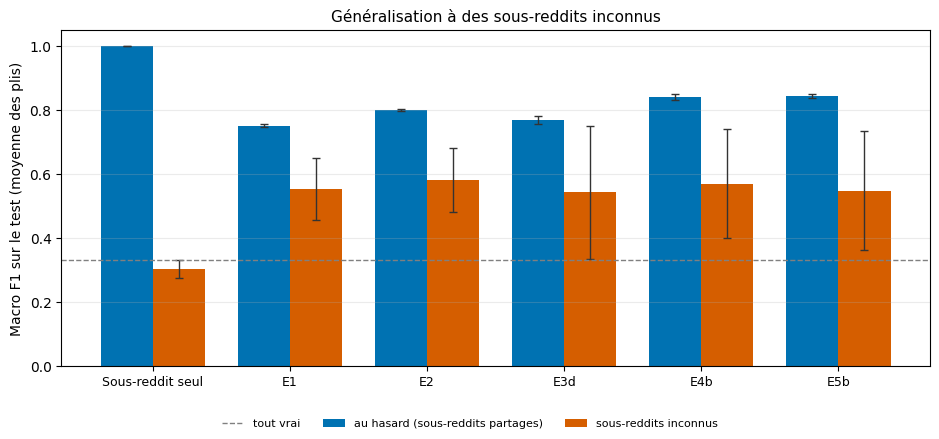

In [7]:
# Cellule 7 : figure de synthese
fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(MODELES)); larg = 0.38
for dec, couleur, decal, lib in (("aleatoire", "#0072B2", -larg / 2, "au hasard (sous-reddits partages)"),
                                 ("sous_reddits", "#D55E00", larg / 2, "sous-reddits inconnus")):
    moy = [agr(dec, m, "macro_f1")[0] for m in MODELES]
    sd = [agr(dec, m, "macro_f1")[1] for m in MODELES]
    ax.bar(x + decal, moy, larg, yerr=sd, capsize=3, color=couleur, label=lib, error_kw=dict(lw=1, ecolor="#333"))
ax.axhline(pl_a, color="grey", ls="--", lw=1, label="tout vrai")
ax.set_xticks(x); ax.set_xticklabels(MODELES, fontsize=9)
ax.set_ylabel("Macro F1 sur le test (moyenne des plis)"); ax.set_ylim(0, 1.05)
ax.set_title("Généralisation à des sous-reddits inconnus", fontsize=11)
ax.grid(axis="y", alpha=0.25)
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(OUT + "figures/rq4_generalisation.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Cellule 8 : fichiers de resultats (metriques completes, tableau par sous-reddit, JSON pour MLflow)
def slug(t):
    return "_".join(unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode().lower().replace("-", " ").split())

met = dict(n_plis=K, n_sous_reddits=int(len(t_sub)), plancher_f1_hasard=pl_a, plancher_f1_sous_reddits=pl_s)
for m in MODELES:
    fa = agr("aleatoire", m, "macro_f1")[0]; fs = agr("sous_reddits", m, "macro_f1")[0]
    met["f1_%s_aleatoire" % slug(m)] = fa
    met["f1_%s_sous_reddits" % slug(m)] = fs
    met["auc_%s_aleatoire" % slug(m)] = agr("aleatoire", m, "auc")[0]
    met["auc_%s_sous_reddits" % slug(m)] = agr("sous_reddits", m, "auc")[0]
    met["variation_f1_pts_%s" % slug(m)] = 100 * (fs - fa)

params = dict(entree="titre + image", decoupage="K plis par sous-reddit contre K plis au hasard (controle)", K=K,
              modeles="sous-reddit seul, E1 TF-IDF, E2 DistilBERT, E3d CLIP, E4b fusion precoce, E5b fusion tardive",
              graine=SEED, n_publications=N)
with open(OUT + "results/mlflow/resultat_RQ4_sous_reddits_inconnus.json", "w", encoding="utf-8") as f:
    json.dump(dict(etape="RQ4", nom="sous_reddits_inconnus", params=params, metrics=met,
                   tags=dict(source="notebook Kaggle 08_rq4_sous_reddits")), f, indent=2, ensure_ascii=False)

log = dict(seed=SEED, K=K, n_sous_reddits=int(len(t_sub)), plancher_f1=dict(aleatoire=pl_a, sous_reddits=pl_s),
           resultats={d: {m: resultats[d][m] for m in MODELES} for d in DECOUPAGES},
           plis=infos, composition_plis=comp,
           sous_reddits={s: dict(publications=int(r["n"]), part_vrai=float(r["part_vrai"]), classe=int(r["classe"]),
                                 pli=int(pli_sr[sub_all == s][0])) for s, r in t_sub.iterrows()})
with open(OUT + "results/rq4_metrics.json", "w", encoding="utf-8") as f:
    json.dump(log, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))
tab_sub.to_csv(OUT + "results/rq4_par_sous_reddit.csv", encoding="utf-8")

for root, _, files in os.walk(OUT):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(p, round(os.path.getsize(p) / 1e6, 2), "Mo")

/kaggle/working/__notebook__.ipynb 0.08 Mo
/kaggle/working/results/rq4_metrics.json 0.01 Mo
/kaggle/working/results/rq4_par_sous_reddit.csv 0.0 Mo
/kaggle/working/results/mlflow/resultat_RQ4_sous_reddits_inconnus.json 0.0 Mo
/kaggle/working/figures/rq4_generalisation.png 0.05 Mo
